# 🏪 Fase 2 — Segmentación RFM + K-Means
## Prueba Técnica Pragma · Analítica de Banca Digital

**Objetivo**: Segmentar los **3 015 comercios** afiliados en grupos homogéneos usando métricas  
**RFM** (Recencia, Frecuencia, Monetario) y el algoritmo **K-Means**, con el fin de identificar  
patrones de comportamiento transaccional y diseñar estrategias diferenciadas para alcanzar  
un **+50 % en comisiones generadas** por la API de pagos Pragma (tasa fija del 5 %).

### Plan de ejecución

| Paso | Descripción |
|------|-------------|
| 1 | Carga y validación de `comercios_segmented_prep.csv` |
| 2 | Exploración rápida — distribuciones, nulos, estadísticas |
| 3 | Análisis de multicolinealidad → exclusión de features redundantes |
| 4 | Análisis de outliers en `monetary` |
| 5 | Preparación de features (`np.log1p` si skew > 1) |
| 6 | Escalado con `RobustScaler` |
| 7 | Determinación de K óptimo (Elbow + Silhouette) |
| 8 | Entrenamiento K-Means (`random_state=42`) |
| 9 | Perfilamiento de segmentos + KPIs de negocio |
| 10 | Exportación de artefactos |
| 11 | Conclusiones y recomendaciones accionables |
| 12 | *(Opcional)* Análisis de sensibilidad — log-transform ON vs OFF |
| 13 | *(Opcional)* Visualización 2D con PCA |

> ⚠️ **Ejecución iterativa recomendada**: correr celda a celda y revisar cada output antes de avanzar.

In [1]:
# ============================================================================
# Librerías y Configuración Global
# ============================================================================
from __future__ import annotations

import json
import warnings
from datetime import datetime
from pathlib import Path
from typing import Optional

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats as sp_stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import RobustScaler, StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)

# ---------------------------------------------------------------------------
# ⚙️  Parámetros configurables — modificar AQUÍ antes de ejecutar
# ---------------------------------------------------------------------------
LOG_TRANSFORM   = True          # Aplicar np.log1p() a vars con skew > SKEW_THRESHOLD
SCALE_METHOD    = "robust"      # "standard" | "robust"
K_RANGE         = range(2, 11)  # Rango de K a evaluar
RANDOM_STATE    = 42
SKEW_THRESHOLD  = 1.0           # Umbral de asimetría para activar log-transform
CORR_THRESHOLD  = 0.85          # Umbral para detectar multicolinealidad

# ---------------------------------------------------------------------------
# 📂 Rutas
# ---------------------------------------------------------------------------
BASE_DIR  = Path("..")
DATA_DIR  = BASE_DIR / "data" / "processed"
PLOTS_DIR = DATA_DIR / "plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

# ---------------------------------------------------------------------------
# Mapeo: columna CSV (español) → nombre canónico del análisis
# ---------------------------------------------------------------------------
COL_MAP: dict = {
    "recencia_dias"            : "recency_days",
    "frecuencia"               : "frequency",
    "monetary"                 : "monetary",
    "ticket_promedio"          : "ticket_avg",
    "comision_generada"        : "commission",
    "n_terminals"              : "n_terminals",
    "actividad_mensual_promedio": "monthly_activity",
    "meses_activos"            : "active_months",
}

sns.set_theme(style="whitegrid", palette="tab10", font_scale=1.1)
PALETTE = sns.color_palette("tab10")

print("✅ Configuración cargada")
print(f"   DATA_DIR  : {DATA_DIR.resolve()}")
print(f"   PLOTS_DIR : {PLOTS_DIR.resolve()}")
print(f"   LOG_TRANSFORM={LOG_TRANSFORM} | SCALE_METHOD='{SCALE_METHOD}' | K_RANGE={list(K_RANGE)}")

✅ Configuración cargada
   DATA_DIR  : C:\Users\johan\OneDrive\Documentos\prueba-tecnica-pragma\data\processed
   PLOTS_DIR : C:\Users\johan\OneDrive\Documentos\prueba-tecnica-pragma\data\processed\plots
   LOG_TRANSFORM=True | SCALE_METHOD='robust' | K_RANGE=[2, 3, 4, 5, 6, 7, 8, 9, 10]


## 1. Carga y Validación de Datos

Cargamos `comercios_segmented_prep.csv` producido por la **Fase 1 (ETL)**.  
Contiene métricas RFM ya calculadas a nivel de comercio para los últimos 6 meses  
(fecha de corte: **2021-05-01**).

**Validaciones aplicadas:**
- Existencia del archivo en disco
- Presencia de columnas requeridas
- Conteo de valores nulos en features clave
- Comercios con `frequency = 0` (implicarían `ticket_avg` indefinido)

In [2]:
def load_processed_data(filepath: Path) -> pd.DataFrame:
    """Carga y valida el dataset procesado de comercios.

    Renombra las columnas al esquema canónico definido en COL_MAP y
    ejecuta checks básicos de calidad (nulos, frecuencia cero).

    Args:
        filepath: Ruta al archivo CSV procesado.

    Returns:
        DataFrame con columnas renombradas al esquema canónico.

    Raises:
        FileNotFoundError: Si el archivo no existe en disco.
        ValueError: Si faltan columnas requeridas tras la carga.
    """
    if not filepath.exists():
        raise FileNotFoundError(f"Archivo no encontrado: {filepath}")

    df = pd.read_csv(filepath)
    df = df.rename(columns=COL_MAP)

    required = [
        "id_comercio", "recency_days", "frequency", "monetary",
        "ticket_avg", "commission", "n_terminals", "active_months",
    ]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise ValueError(f"Columnas faltantes: {missing}")

    # ── Checks de calidad ─────────────────────────────────────────────────
    null_counts = df[required].isnull().sum()
    print("── Nulos por columna requerida ──────────────────────────────────")
    if null_counts.any():
        print(null_counts[null_counts > 0].to_string())
    else:
        print("  ✅ Sin valores nulos")

    zero_freq = (df["frequency"] == 0).sum()
    if zero_freq:
        print(f"  ⚠️  {zero_freq} comercios con frequency=0 → ticket_avg puede ser Inf/NaN")
    else:
        print("  ✅ Sin frecuencias cero")

    return df


# ── Ejecutar ──────────────────────────────────────────────────────────────
CSV_PATH = DATA_DIR / "comercios_segmented_prep.csv"
df_raw   = load_processed_data(CSV_PATH)
print(f"\n📦 Dataset: {df_raw.shape[0]:,} filas × {df_raw.shape[1]} columnas")

── Nulos por columna requerida ──────────────────────────────────
  ✅ Sin valores nulos
  ✅ Sin frecuencias cero

📦 Dataset: 3,015 filas × 20 columnas


## 2. Exploración Rápida del Dataset

Revisamos estructura general, estadísticas descriptivas y distribuciones de las variables  
RFM **antes** de cualquier transformación.  
Los valores de **skewness** revelarán qué variables requieren log-transform.

,id_comercio,fecha_creacion,fecha_primera_transaccion,monto_ventas_acumulado,monto_ventas_ultimo_mes,categoria_comercio,sub_categoria_comercio,ciudad,id_terminals,n_terminals,registros_origen,duplicated_flag,ultima_transaccion,recency_days,frequency,active_months,monetary,ticket_avg,commission,monthly_activity
0,003QDVFJCJ,2021-03-26 12:17:00,2021-03-26 12:42:00,6542000.0,1240000.0,Comercio detallista,Ropa / Accesorios,Bogotá D.C.,['01299'],1,[0],False,2021-05-01,0,30,3,6542000.0,218066.67,327100.0,10.00
1,008LJH6YHN,2021-02-10 15:15:00,2021-02-10 15:34:00,4380000.0,1102000.0,Belleza y cuidado personal,Spa,Bogotá D.C.,['00591'],1,[1],False,2021-05-01,0,10,4,4380000.0,438000.00,219000.0,2.50
2,00B3DGV62G,2021-03-03 15:09:00,2021-03-03 15:30:00,11892500.0,1297000.0,Comercio detallista,Auto partes,Bogotá D.C.,['02130'],1,[2],False,2021-05-01,0,65,3,11892500.0,182961.54,594625.0,21.67


<class 'pandas.DataFrame'>
RangeIndex: 3015 entries, 0 to 3014
Columns: 20 entries, id_comercio to monthly_activity
dtypes: bool(1), float64(6), int64(4), str(9)
memory usage: 450.6 KB

─── Resumen estadístico ───────────────────────────────────────────


,recency_days,frequency,monetary,ticket_avg,commission,n_terminals,active_months,monthly_activity
count,3015.00,3015.0,3.015000e+03,3015.00,3015.00,3015.00,3015.00,3015.00
mean,18.71,22.6,4.388275e+06,247684.79,219413.77,1.02,2.77,6.80
std,32.56,43.2,7.785727e+06,635131.40,389286.35,0.16,1.21,11.65
min,0.00,1.0,0.000000e+00,0.00,0.00,1.00,1.00,1.00
25%,0.00,3.0,3.257000e+05,39802.25,16285.00,1.00,2.00,1.67
50%,0.00,10.0,1.554000e+06,120727.27,77700.00,1.00,3.00,3.33
75%,30.00,23.0,4.976200e+06,301230.71,248810.00,1.00,3.00,7.00
max,151.00,740.0,1.041809e+08,29002000.00,5209045.00,5.00,6.00,181.67


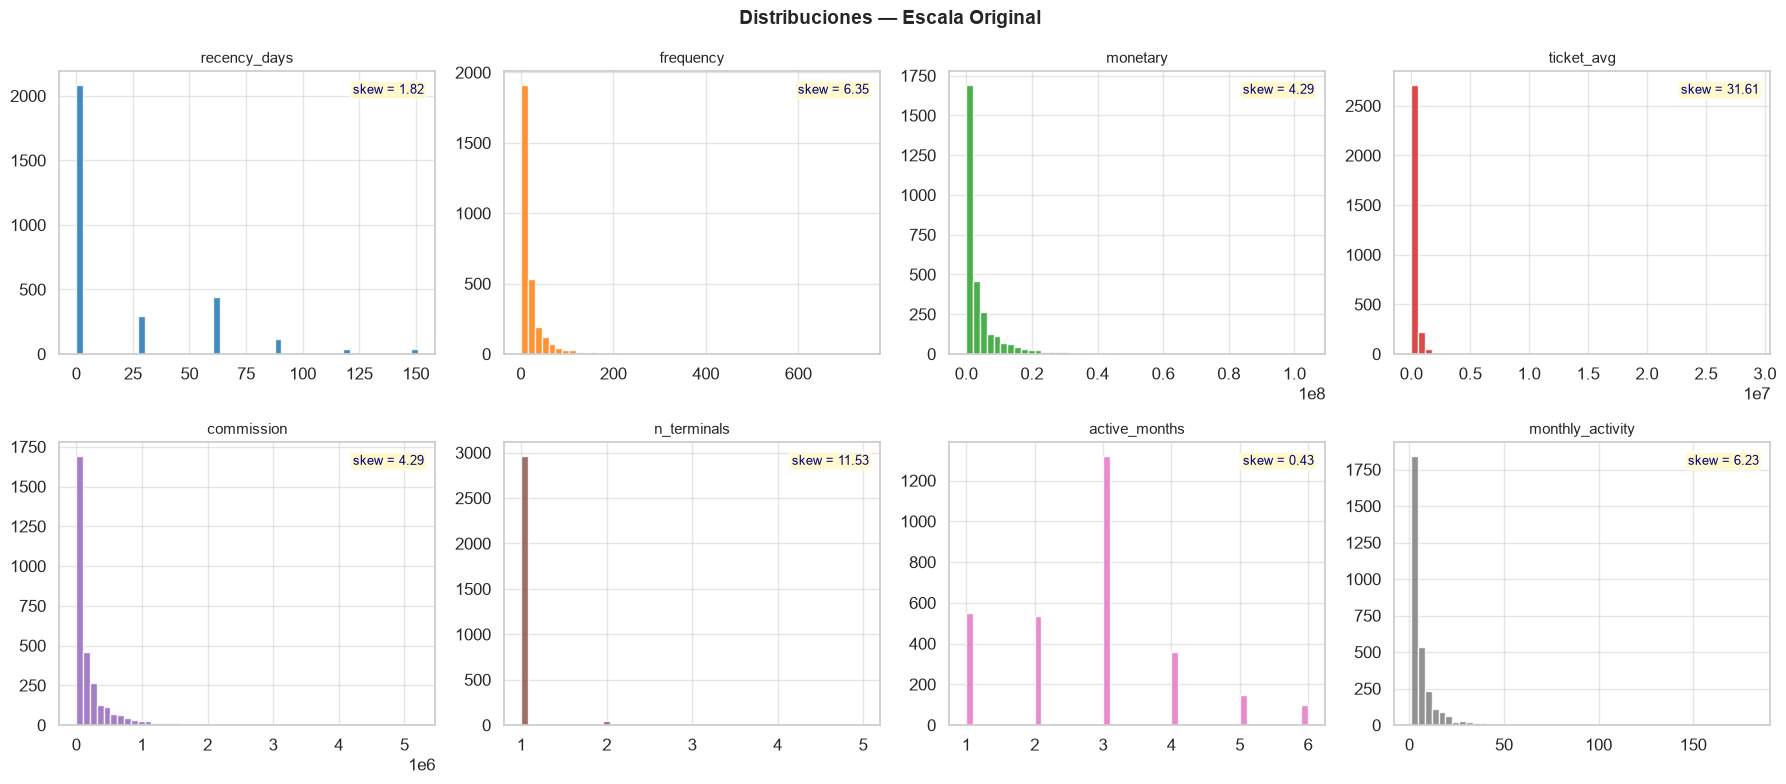


📊 Guardado: ..\data\processed\plots\distributions_raw.png


In [3]:
# ── Vista general ──────────────────────────────────────────────────────────
display(df_raw.head(3))
df_raw.info(verbose=False, show_counts=True)

# ── Estadísticas descriptivas ─────────────────────────────────────────────
rfm_cols = [
    "recency_days", "frequency", "monetary", "ticket_avg",
    "commission", "n_terminals", "active_months", "monthly_activity",
]
print("\n─── Resumen estadístico ───────────────────────────────────────────")
display(df_raw[rfm_cols].describe().round(2))

# ── Histogramas ───────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
fig.suptitle("Distribuciones — Escala Original", fontsize=14, fontweight="bold")

for ax, col in zip(axes.flatten(), rfm_cols):
    skew_val = df_raw[col].skew()
    color    = PALETTE[rfm_cols.index(col) % 10]
    ax.hist(df_raw[col].dropna(), bins=50, color=color, edgecolor="white", alpha=0.85)
    ax.set_title(col, fontsize=11)
    bbox_style = dict(boxstyle="round,pad=0.2", fc="#fff9c4", alpha=0.85)
    ax.annotate(
        f"skew = {skew_val:.2f}",
        xy=(0.97, 0.92), xycoords="axes fraction",
        ha="right", fontsize=9, color="navy", bbox=bbox_style,
    )

plt.tight_layout()
dist_path = PLOTS_DIR / "distributions_raw.png"
plt.savefig(dist_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"\n📊 Guardado: {dist_path}")

## 3. Análisis de Multicolinealidad

Calculamos la **matriz de correlación de Pearson** entre todas las features candidatas.  
Umbral de alerta: |r| > 0.85.

**Hallazgos esperados (verificados empíricamente en el dataset):**

| Par | r | Decisión |
|-----|---|----------|
| `commission` ↔ `monetary` | **1.000** | Excluir `commission` del entrenamiento — es `monetary × 0.05` (tasa fija del ETL) |
| `monthly_activity` ↔ `frequency` | **≈0.954** | Excluir `monthly_activity` — redundante con `frequency` |
| `monetary` ↔ `ticket_avg` | ≈0.296 | Mantener ambas — baja correlación |

> **Features finales para K-Means:** `recency_days`, `frequency`, `monetary`,  
> `ticket_avg`, `n_terminals`, `active_months` (**6 variables**)

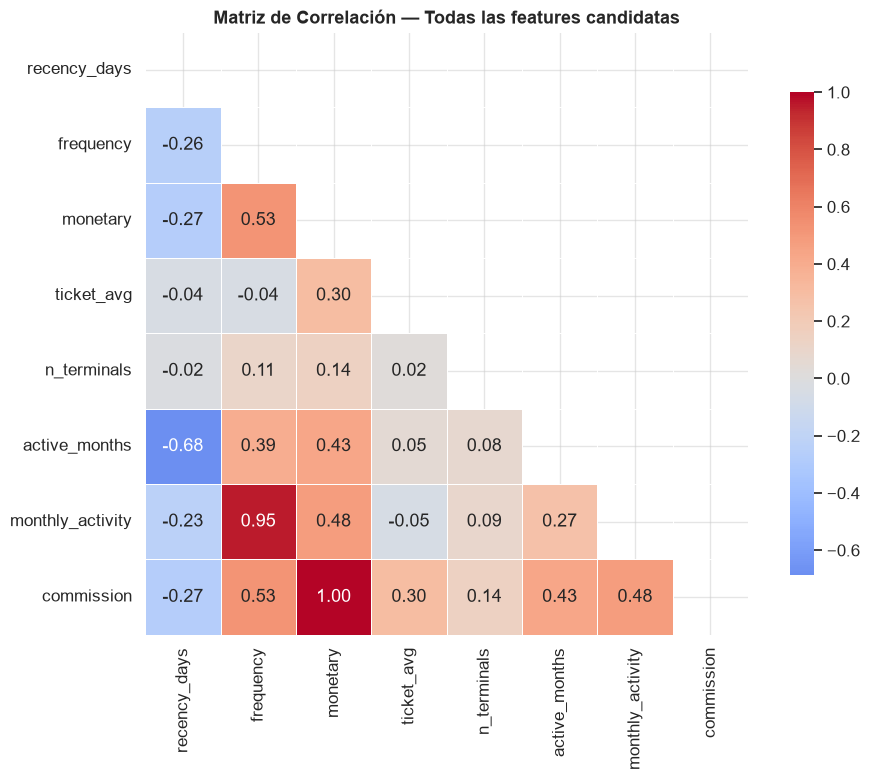

📊 Guardado: ..\data\processed\plots\correlation_matrix.png

⚠️  Pares con |r| > 0.85:
   frequency                    ↔ monthly_activity              r = +0.9536
   monetary                     ↔ commission                    r = +1.0000

✅ Features seleccionadas para K-Means (6): ['recency_days', 'frequency', 'monetary', 'ticket_avg', 'n_terminals', 'active_months']


In [4]:
ALL_CANDIDATES = [
    "recency_days", "frequency", "monetary", "ticket_avg",
    "n_terminals", "active_months", "monthly_activity", "commission",
]

corr_matrix = df_raw[ALL_CANDIDATES].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0,
    mask=mask, linewidths=0.5, ax=ax, square=True,
    cbar_kws={"shrink": 0.8},
)
ax.set_title("Matriz de Correlación — Todas las features candidatas",
             fontsize=13, fontweight="bold")
plt.tight_layout()
corr_path = PLOTS_DIR / "correlation_matrix.png"
plt.savefig(corr_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"📊 Guardado: {corr_path}\n")

# ── Detectar pares de alta correlación ───────────────────────────────────
high_corr_pairs = []
cols = corr_matrix.columns.tolist()
for i in range(len(cols)):
    for j in range(i + 1, len(cols)):
        r = corr_matrix.iloc[i, j]
        if abs(r) > CORR_THRESHOLD:
            high_corr_pairs.append((cols[i], cols[j], round(float(r), 4)))

if high_corr_pairs:
    print(f"⚠️  Pares con |r| > {CORR_THRESHOLD}:")
    for c1, c2, r in high_corr_pairs:
        print(f"   {c1:<28} ↔ {c2:<28}  r = {r:+.4f}")
else:
    print(f"✅ No hay pares con |r| > {CORR_THRESHOLD}")

# ── Decisión final de features ────────────────────────────────────────────
FEATURE_COLS = ["recency_days", "frequency", "monetary",
                "ticket_avg", "n_terminals", "active_months"]
print(f"\n✅ Features seleccionadas para K-Means ({len(FEATURE_COLS)}): {FEATURE_COLS}")

## 4. Análisis de Outliers en `monetary`

Identificamos el **top 0.1 %** de comercios por `monetary` para decidir el tratamiento.

**Opciones:**
1. ✅ **(Elegida)** Aplicar `np.log1p()` — comprime la escala sin perder observaciones
2. ❌ Excluir outliers — pierde comercios de alto valor estratégico
3. ❌ Winsorizar — altera los valores reales, dificulta la interpretación de negocio

> Los comercios de altísimo volumen son exactamente los más relevantes para la meta  
> de **+50 % en comisiones**. No deben ser excluidos.

Distribución de percentiles — monetary:
  P50  (mediana)  : $       1,554,000
  P95             : $      18,511,800
  P99             : $      36,868,507
  P99.9 (top 0.1%): $      66,760,430
  Máximo          : $     104,180,900

Comercios en top 0.1 %: 4


,id_comercio,monetary,frequency,recency_days,ticket_avg,commission,active_months,n_terminals
2799,XFZCYU819H,104180900.0,237,0,439581.86,5209045.0,5,3
1220,E73K1PXPMQ,80330200.0,31,0,2591296.77,4016510.0,6,1
2139,PAFLWUILLV,74277300.0,47,0,1580368.09,3713865.0,3,1
2960,ZBB5JOFDMW,66773400.0,211,0,316461.61,3338670.0,3,1


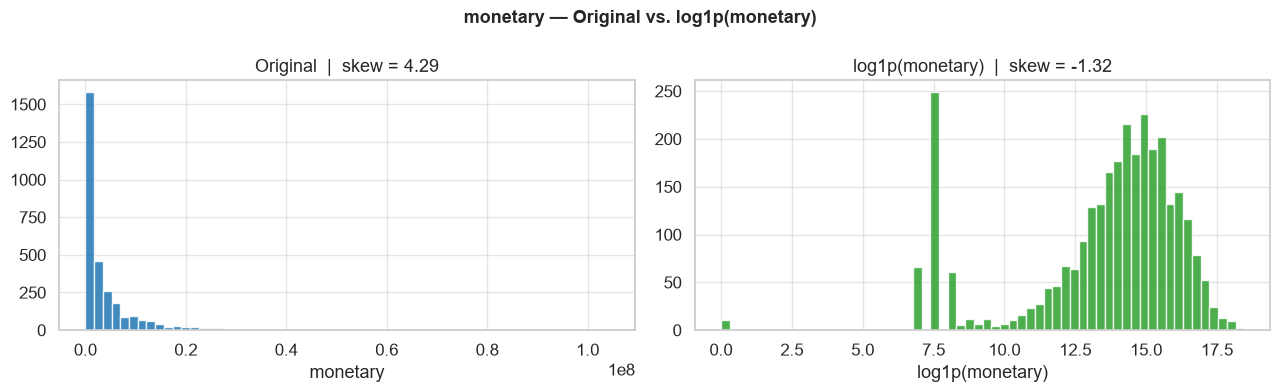


→ Decisión: aplicar np.log1p() — outliers se mantienen en el dataset.


In [6]:
q95  = df_raw["monetary"].quantile(0.95)
q99  = df_raw["monetary"].quantile(0.99)
q999 = df_raw["monetary"].quantile(0.999)

print("Distribución de percentiles — monetary:")
print(f"  P50  (mediana)  : ${df_raw['monetary'].median():>16,.0f}")
print(f"  P95             : ${q95:>16,.0f}")
print(f"  P99             : ${q99:>16,.0f}")
print(f"  P99.9 (top 0.1%): ${q999:>16,.0f}")
print(f"  Máximo          : ${df_raw['monetary'].max():>16,.0f}")

top_outliers = (
    df_raw[df_raw["monetary"] > q999]
    [["id_comercio", "monetary", "frequency", "recency_days","ticket_avg", "commission", "active_months","n_terminals"]]
    .sort_values("monetary", ascending=False)
)
print(f"\nComercios en top 0.1 %: {len(top_outliers)}")
display(top_outliers)

# Comparación visual: escala original vs log1p
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
fig.suptitle("monetary — Original vs. log1p(monetary)", fontsize=13, fontweight="bold")

axes[0].hist(df_raw["monetary"], bins=60, color=PALETTE[0], edgecolor="white", alpha=0.85)
axes[0].set_title(f"Original  |  skew = {df_raw['monetary'].skew():.2f}")
axes[0].set_xlabel("monetary")

log_monetary = np.log1p(df_raw["monetary"])
axes[1].hist(log_monetary, bins=60, color=PALETTE[2], edgecolor="white", alpha=0.85)
axes[1].set_title(f"log1p(monetary)  |  skew = {log_monetary.skew():.2f}")
axes[1].set_xlabel("log1p(monetary)")

plt.tight_layout()
plt.savefig(PLOTS_DIR / "monetary_log_comparison.png", dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print("\n→ Decisión: aplicar np.log1p() — outliers se mantienen en el dataset.")

## 5. Preparación de Features para Clustering

Aplicamos `np.log1p(x)` a todas las variables con **skewness > `SKEW_THRESHOLD`** (1.0).  
`log1p(x) = log(1 + x)` es seguro para valores ≥ 0 y comprime distribuciones con cola larga.

| Variable | Skew original | Acción | Motivo |
|----------|:---:|:---:|--------|
| `ticket_avg` | **31.6** | ✅ `log1p` | Cola extremadamente larga |
| `n_terminals` | **11.5** | ✅ `log1p` | Mayoría tiene 1 terminal, pocos tienen muchas |
| `frequency` | **6.3** | ✅ `log1p` | Alta concentración en valores bajos |
| `monetary` | **4.3** | ✅ `log1p` | Documentado en sección anterior |
| `recency_days` | **1.8** | ✅ `log1p` | Ligera cola derecha |
| `active_months` | **0.4** | ❌ sin transform | Distribución casi simétrica |

La función devuelve `transform_info` para trazabilidad completa.


In [38]:
def prepare_features(
    df: pd.DataFrame,
    feature_cols: Optional[list] = None,
    log_transform: bool = True,
    skew_threshold: float = 1.0,
) -> tuple:
    """Prepara el conjunto de features para K-Means.

    Aplica transformación logarítmica (np.log1p) a las variables con asimetría
    superior al umbral configurado. Excluye por diseño las variables
    `commission` (r=1.0 con monetary) y `monthly_activity` (r=0.95 con frequency).

    Args:
        df: DataFrame con columnas canónicas (post COL_MAP).
        feature_cols: Lista de features a usar. Valor por defecto:
            ['recency_days', 'frequency', 'monetary', 'ticket_avg',
             'n_terminals', 'active_months'].
        log_transform: Si True, aplica np.log1p() a features con skew > skew_threshold.
        skew_threshold: Umbral de asimetría para activar la transformación.

    Returns:
        Tuple de tres elementos:
            - X (pd.DataFrame): Features transformadas, listas para escalar.
            - transform_info (dict): Diccionario con skewness original/post-transform
              y lista de variables transformadas.
            - df_orig (pd.DataFrame): Copia del df original sin modificar
              (para perfilamiento post-clustering).
    """
    if feature_cols is None:
        feature_cols = [
            "recency_days", "frequency", "monetary",
            "ticket_avg", "n_terminals", "active_months",
        ]

    df_orig = df.copy()
    df_work = df[["id_comercio"] + feature_cols].copy()

    transform_info: dict = {
        "features_used"       : feature_cols,
        "log_transformed"     : [],
        "skewness_original"   : {},
        "skewness_after"      : {},
        "log_transform_enabled": log_transform,
        "skew_threshold"      : skew_threshold,
    }

    for col in feature_cols:
        sk_orig = float(df_work[col].skew())
        transform_info["skewness_original"][col] = round(sk_orig, 3)

        if log_transform and sk_orig > skew_threshold:
            df_work[col] = np.log1p(df_work[col])
            transform_info["log_transformed"].append(col)

        transform_info["skewness_after"][col] = round(float(df_work[col].skew()), 3)

    X = df_work[feature_cols].reset_index(drop=True)
    return X, transform_info, df_orig

In [39]:
# ── Ejecutar ──────────────────────────────────────────────────────────────
X, transform_info, df_orig = prepare_features(
    df_raw, log_transform=LOG_TRANSFORM, skew_threshold=SKEW_THRESHOLD
)

# ── Resumen de transformaciones ───────────────────────────────────────────
print("=" * 60)
print("RESUMEN DE TRANSFORMACIONES DE FEATURES")
print("=" * 60)

skew_summary = pd.DataFrame({
    "skew_original" : transform_info["skewness_original"],
    "skew_post"     : transform_info["skewness_after"],
    "log1p_aplicado": {
        c: (c in transform_info["log_transformed"])
        for c in transform_info["features_used"]
    },
})
display(skew_summary)

print(f"\nVariables transformadas : {transform_info['log_transformed']}")
print(f"Umbral skewness usado   : {transform_info['skew_threshold']}")
print(f"Shape de X              : {X.shape}")
display(X.describe().round(3))

RESUMEN DE TRANSFORMACIONES DE FEATURES


,skew_original,skew_post,log1p_aplicado
recency_days,1.825,0.893,True
frequency,6.347,0.402,True
monetary,4.288,-1.324,True
ticket_avg,31.612,-1.393,True
n_terminals,11.529,9.172,True
active_months,0.432,0.432,False



Variables transformadas : ['recency_days', 'frequency', 'monetary', 'ticket_avg', 'n_terminals']
Umbral skewness usado   : 1.0
Shape de X              : (3015, 6)


,recency_days,frequency,monetary,ticket_avg,n_terminals,active_months
count,3015.000,3015.000,3015.000,3015.000,3015.000,3015.000
mean,1.237,2.412,13.507,11.286,0.700,2.772
std,1.872,1.165,2.855,1.979,0.059,1.210
min,0.000,0.693,0.000,0.000,0.693,1.000
25%,0.000,1.386,12.694,10.592,0.693,2.000
50%,0.000,2.398,14.256,11.701,0.693,3.000
75%,3.434,3.178,15.420,12.616,0.693,3.000
max,5.024,6.608,18.462,17.183,1.792,6.000


## 6. Escalado de Variables

Escalamos con **`RobustScaler`** (por defecto, configurable) ya que:
- Se detectaron outliers significativos en `monetary`, `ticket_avg` y `n_terminals`.
- `RobustScaler` usa **mediana e IQR** en lugar de media/std → menos sensible a valores extremos.
- `StandardScaler` sería apropiado si la distribución fuera aproximadamente Normal post-transform.

In [25]:
def scale_features(X: pd.DataFrame, method: str = "standard") -> tuple:
    """Escala las features para clustering.

    Args:
        X: DataFrame de features ya transformadas (post log1p si aplica).
        method: Método de escalado. Opciones: 'standard' (StandardScaler)
            o 'robust' (RobustScaler).

    Returns:
        Tuple (X_scaled, scaler) donde:
            - X_scaled (np.ndarray): Array 2D de features escaladas.
            - scaler: Objeto sklearn ajustado (para inversión si se requiere).

    Raises:
        ValueError: Si method no es 'standard' ni 'robust'.
    """
    if method == "standard":
        scaler = StandardScaler()
    elif method == "robust":
        scaler = RobustScaler()
    else:
        raise ValueError(f"method debe ser 'standard' o 'robust'; recibido: '{method}'")

    X_scaled = scaler.fit_transform(X)
    return X_scaled, scaler


# ── Ejecutar ──────────────────────────────────────────────────────────────
X_scaled, scaler = scale_features(X, method=SCALE_METHOD)

print(f"✅ Escalado con {type(scaler).__name__}")
print(f"   Shape     : {X_scaled.shape}")
print(f"   Media/col : {X_scaled.mean(axis=0).round(4)}")
print(f"   Std/col   : {X_scaled.std(axis=0).round(4)}")

✅ Escalado con RobustScaler
   Shape     : (3015, 6)
   Media/col : [ 0.3601  0.0081 -0.275  -0.2052  0.0072 -0.2282]
   Std/col   : [0.5451 0.6502 1.047  0.9774 0.0586 1.2096]


## 7. Determinación del K Óptimo

Evaluamos K ∈ {2, …, 10} con dos criterios complementarios:

| Criterio | Descripción | Interpretación |
|----------|-------------|----------------|
| **Inercia (Elbow)** | WCSS — suma de distancias al centroide más cercano | Buscar el "codo" donde la reducción marginal se aplana |
| **Silhouette Score** | Cohesión interna vs. separación entre clusters (rango −1 a +1) | Preferir el K con el **mayor valor** |

Ambos criterios deben coincidir o estar próximos para elegir K con confianza.

In [26]:
def evaluate_k(
    X_scaled: np.ndarray,
    k_range: range = range(2, 11),
    random_state: int = 42,
    save_path: Optional[Path] = None,
) -> pd.DataFrame:
    """Evalúa el K óptimo con inercia y Silhouette Score.

    Genera y guarda un gráfico combinado (Elbow izquierda, Silhouette derecha).
    Marca automáticamente el K con mayor Silhouette Score.

    Args:
        X_scaled: Array 2D de features escaladas.
        k_range: Rango de K a evaluar (default: range(2, 11)).
        random_state: Semilla para reproducibilidad de KMeans.
        save_path: Ruta para guardar el gráfico .png. Si None, no guarda.

    Returns:
        DataFrame con columnas ['k', 'inertia', 'silhouette'].
    """
    inertias, silhouettes = [], []

    for k in k_range:
        km = KMeans(n_clusters=k, init="k-means++", n_init=10,
                    random_state=random_state)
        lbl = km.fit_predict(X_scaled)
        inertias.append(km.inertia_)
        silhouettes.append(silhouette_score(X_scaled, lbl))
        print(f"  K={k:2d} | inertia={km.inertia_:>12,.2f} | silhouette={silhouettes[-1]:.4f}")

    metrics_df = pd.DataFrame(
        {"k": list(k_range), "inertia": inertias, "silhouette": silhouettes}
    )

    # ── Gráfico combinado ─────────────────────────────────────────────────
    best_k = int(metrics_df.loc[metrics_df["silhouette"].idxmax(), "k"])

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))
    fig.suptitle("Determinación del K Óptimo", fontsize=14, fontweight="bold")

    # Elbow
    ax1.plot(metrics_df["k"], metrics_df["inertia"],
             marker="o", color="#2980b9", linewidth=2, markersize=7)
    ax1.set_xlabel("K (número de clusters)")
    ax1.set_ylabel("Inercia (WCSS)")
    ax1.set_title("Método del Codo")
    ax1.set_xticks(list(k_range))
    ax1.grid(True, alpha=0.4)

    # Silhouette
    bar_colors = ["#e74c3c" if k == best_k else "#3498db"
                  for k in metrics_df["k"]]
    ax2.bar(metrics_df["k"], metrics_df["silhouette"],
            color=bar_colors, edgecolor="white", width=0.6)
    ax2.set_xlabel("K (número de clusters)")
    ax2.set_ylabel("Silhouette Score")
    ax2.set_title("Índice de Silhouette")
    ax2.set_xticks(list(k_range))
    ax2.grid(True, alpha=0.4, axis="y")
    best_sil = float(metrics_df.loc[metrics_df["silhouette"].idxmax(), "silhouette"])
    ax2.annotate(
        f"K óptimo = {best_k}\n({best_sil:.4f})",
        xy=(best_k, best_sil),
        xytext=(best_k + 0.5, best_sil - 0.015),
        fontsize=9, color="#c0392b", fontweight="bold",
        arrowprops=dict(arrowstyle="->", color="#c0392b"),
    )

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=120, bbox_inches="tight")
        print(f"\n📊 Guardado: {save_path}")
    display(plt.gcf())
    plt.close()

    return metrics_df

⏳ Evaluando K ∈ [2, 3, 4, 5, 6, 7, 8, 9, 10] ...

  K= 2 | inertia=    6,007.20 | silhouette=0.5423
  K= 3 | inertia=    4,068.34 | silhouette=0.4184
  K= 4 | inertia=    2,965.03 | silhouette=0.4086
  K= 5 | inertia=    2,536.79 | silhouette=0.3491
  K= 6 | inertia=    2,256.44 | silhouette=0.3538
  K= 7 | inertia=    2,012.34 | silhouette=0.3479
  K= 8 | inertia=    1,830.50 | silhouette=0.3475
  K= 9 | inertia=    1,614.80 | silhouette=0.3571
  K=10 | inertia=    1,490.81 | silhouette=0.3672

📊 Guardado: ..\data\processed\plots\elbow_silhouette.png


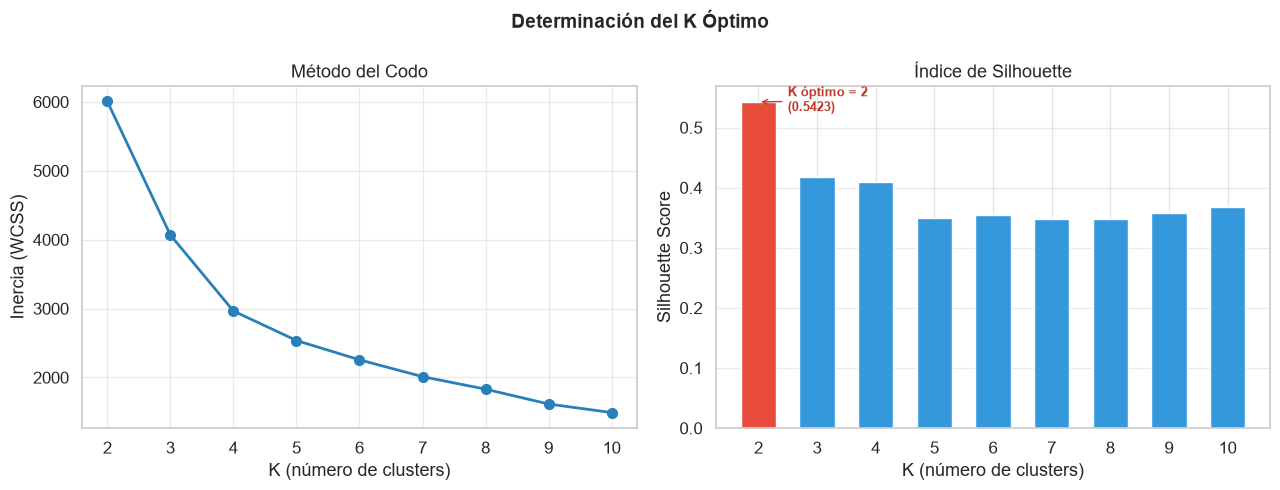


─── Tabla completa de métricas ──────────────────────────────────


,inertia,silhouette
k,,
2,6007.2033,0.5423
3,4068.3439,0.4184
4,2965.0337,0.4086
5,2536.7895,0.3491
6,2256.4355,0.3538
7,2012.3449,0.3479
8,1830.5005,0.3475
9,1614.7978,0.3571
10,1490.8091,0.3672



🏆 K sugerido por Silhouette Score: K = 2


In [27]:
print(f"⏳ Evaluando K ∈ {list(K_RANGE)} ...")
print()
metrics_df = evaluate_k(
    X_scaled,
    k_range=K_RANGE,
    random_state=RANDOM_STATE,
    save_path=PLOTS_DIR / "elbow_silhouette.png",
)

best_k_silhouette = int(metrics_df.loc[metrics_df["silhouette"].idxmax(), "k"])
print(f"\n─── Tabla completa de métricas ──────────────────────────────────")
display(metrics_df.set_index("k").round(4))
print(f"\n🏆 K sugerido por Silhouette Score: K = {best_k_silhouette}")

## 8. Entrenamiento K-Means

Selecciona el **K óptimo** revisando:
1. La curva de inercia — el "codo" indica donde agregar más clusters ya no reduce WCSS significativamente.
2. El mayor Silhouette Score — mayor cohesión interna y separación entre clusters.

> **Configura `K_SELECTED` en la siguiente celda** basándote en los gráficos anteriores.  
> La variable `best_k_silhouette` contiene la sugerencia automática.

In [28]:
def train_kmeans(
    X_scaled: np.ndarray,
    K: int,
    random_state: int = 42,
) -> tuple:
    """Entrena K-Means con el K seleccionado.

    Usa inicialización k-means++ para convergencia más rápida y robusta.

    Args:
        X_scaled: Array 2D de features escaladas (mismo que en evaluate_k).
        K: Número de clusters a generar.
        random_state: Semilla para reproducibilidad. Default: 42.

    Returns:
        Tuple (model, labels) donde:
            - model (KMeans): Objeto KMeans ya ajustado.
            - labels (np.ndarray): Array 1D con asignación de cluster (base-0).
    """
    model = KMeans(
        n_clusters=K,
        init="k-means++",
        n_init=10,
        max_iter=300,
        random_state=random_state,
    )
    labels = model.fit_predict(X_scaled)
    return model, labels

In [29]:
# ── ⚙️  CONFIGURA K AQUÍ — revisa elbow_silhouette.png antes de cambiar ──
K_SELECTED = best_k_silhouette   # ajusta manualmente si el codo sugiere otro valor

print(f"Entrenando K-Means  K={K_SELECTED}  random_state={RANDOM_STATE} ...")
km_model, labels = train_kmeans(X_scaled, K=K_SELECTED, random_state=RANDOM_STATE)

sil_final = silhouette_score(X_scaled, labels)

print(f"\n✅ Modelo entrenado")
print(f"   Inercia         : {km_model.inertia_:>15,.2f}")
print(f"   Silhouette Score: {sil_final:.4f}")
print(f"\n   Distribución de clusters:")
unique, counts = np.unique(labels, return_counts=True)
for cl, cnt in zip(unique, counts):
    bar = "█" * int(cnt / len(labels) * 40)
    print(f"   Cluster {cl}: {cnt:>4} comercios ({cnt/len(labels)*100:5.1f}%)  {bar}")

Entrenando K-Means  K=2  random_state=42 ...

✅ Modelo entrenado
   Inercia         :        6,007.20
   Silhouette Score: 0.5423

   Distribución de clusters:
   Cluster 0:  626 comercios ( 20.8%)  ████████
   Cluster 1: 2389 comercios ( 79.2%)  ███████████████████████████████


## 9. Perfilamiento de Segmentos

Calculamos estadísticas descriptivas por cluster usando **variables en escala original**  
(pre-transformación) para que los valores sean interpretables por el equipo de negocio.

**Métricas incluidas:**
- `n_comercios` + `% del total`
- `recency_days` — media y mediana (menor = más activo)
- `frequency` — media de transacciones en el período
- `monetary` — media y mediana del monto total
- `ticket_avg` — ticket promedio
- `commission` — comisión total generada + % sobre el total global
- `n_terminals` — terminales promedio por comercio

**KPIs de negocio adicionales:**
- Gap vs. meta +50 % de comisiones
- Tasa de adopción de la API (proxy: `n_terminals / meses_activos`)
- Señal de churn: `recency_days > 60`

In [30]:
def profile_segments(
    df_orig: pd.DataFrame,
    labels: np.ndarray,
    save_dir: Path = PLOTS_DIR,
) -> pd.DataFrame:
    """Genera el perfil descriptivo y KPIs de negocio por segmento.

    Args:
        df_orig: DataFrame con variables en escala natural (pre-transformación).
        labels: Array 1D con asignación de cluster por comercio (base-0).
        save_dir: Directorio donde guardar los gráficos de perfil.

    Returns:
        DataFrame con métricas agregadas y KPIs por cluster.
    """
    df_p = df_orig.copy()
    df_p["cluster"] = labels.astype(int)

    total_commission = df_p["commission"].sum()
    total_comercios  = len(df_p)

    # ── Métricas por cluster ──────────────────────────────────────────────
    profile = (
        df_p.groupby("cluster")
        .agg(
            n_comercios          =("id_comercio"   , "count"),
            recency_days_mean    =("recency_days"  , "mean"),
            recency_days_median  =("recency_days"  , "median"),
            frequency_mean       =("frequency"     , "mean"),
            frequency_median     =("frequency"     , "median"),
            monetary_mean        =("monetary"      , "mean"),
            monetary_median      =("monetary"      , "median"),
            ticket_avg_mean      =("ticket_avg"    , "mean"),
            commission_sum       =("commission"    , "sum"),
            commission_mean      =("commission"    , "mean"),
            n_terminals_mean     =("n_terminals"   , "mean"),
            active_months_mean   =("active_months" , "mean"),
        )
        .reset_index()
    )

    profile["pct_comercios"]  = (profile["n_comercios"] / total_comercios * 100).round(1)
    profile["pct_commission"] = (profile["commission_sum"] / total_commission * 100).round(1)

    # ── KPIs de negocio ───────────────────────────────────────────────────
    meta_commission = total_commission * 1.50  # meta +50%
    profile["gap_to_meta_cop"] = (
        (meta_commission - total_commission) * (profile["pct_commission"] / 100)
    ).round(0)
    profile["churn_signal_pct"] = (
        df_p.groupby("cluster")
        .apply(lambda g: (g["recency_days"] > 60).mean() * 100)
        .values.round(1)
    )
    profile["api_adoption_proxy"] = (
        df_p.groupby("cluster")
        .apply(lambda g: (g["n_terminals"] / g["active_months"].replace(0, 1)).mean())
        .values.round(3)
    )

    # Redondear floats
    float_cols = profile.select_dtypes("float").columns
    profile[float_cols] = profile[float_cols].round(2)

    # ── Guardar CSV ───────────────────────────────────────────────────────
    profiles_path = DATA_DIR / "perfiles_segmentos.csv"
    profile.to_csv(profiles_path, index=False)
    print(f"💾 Guardado: {profiles_path}")

    # ── Gráfico 1: Heatmap normalizado ────────────────────────────────────
    heatmap_cols = [
        "recency_days_mean", "frequency_mean", "monetary_mean",
        "ticket_avg_mean", "commission_mean", "n_terminals_mean",
    ]
    hm_raw  = profile.set_index("cluster")[heatmap_cols]
    hm_norm = (hm_raw - hm_raw.min()) / (hm_raw.max() - hm_raw.min() + 1e-9)

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    fig.suptitle("Perfil de Segmentos", fontsize=14, fontweight="bold")

    sns.heatmap(
        hm_norm.T, annot=hm_raw.T, fmt=".0f", cmap="YlOrRd",
        linewidths=0.5, ax=axes[0], cbar=True,
    )
    axes[0].set_title("Heatmap — valores reales, color normalizado")
    axes[0].set_xlabel("Cluster")

    # ── Gráfico 2: % comisiones por cluster ───────────────────────────────
    colors = [PALETTE[i % 10] for i in range(len(profile))]
    axes[1].bar(
        profile["cluster"].astype(str), profile["pct_commission"],
        color=colors, edgecolor="white", width=0.6,
    )
    axes[1].set_title("% Contribución a Comisiones Totales")
    axes[1].set_xlabel("Cluster")
    axes[1].set_ylabel("% del total de comisiones")
    for _, row in profile.iterrows():
        axes[1].text(
            int(row["cluster"]), row["pct_commission"] + 0.3,
            f"{row['pct_commission']}%",
            ha="center", fontsize=10, fontweight="bold",
        )

    plt.tight_layout()
    profiles_plot = save_dir / "cluster_profiles.png"
    plt.savefig(profiles_plot, dpi=120, bbox_inches="tight")
    display(plt.gcf())
    plt.close()
    print(f"📊 Guardado: {profiles_plot}")

    return profile

💾 Guardado: ..\data\processed\perfiles_segmentos.csv


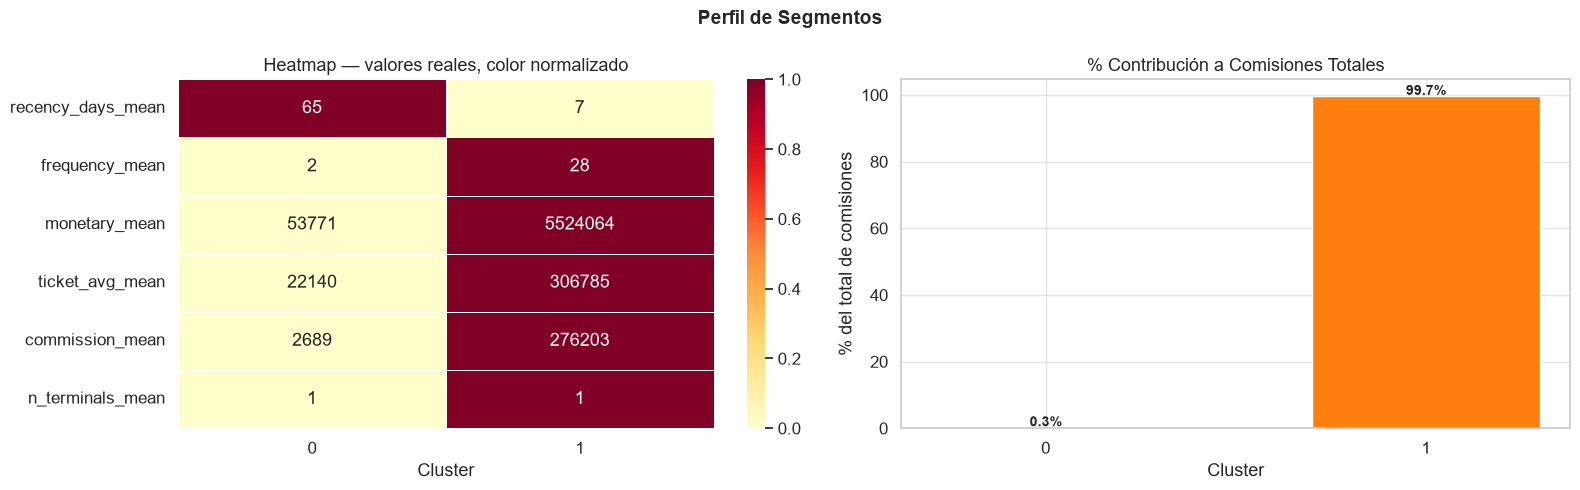

📊 Guardado: ..\data\processed\plots\cluster_profiles.png

═══════════════════════════════════════════════════════════════════
PERFIL DE SEGMENTOS
═══════════════════════════════════════════════════════════════════


,n_comercios,recency_days_mean,recency_days_median,frequency_mean,frequency_median,monetary_mean,monetary_median,ticket_avg_mean,commission_sum,commission_mean,n_terminals_mean,active_months_mean,pct_comercios,pct_commission,gap_to_meta_cop,churn_signal_pct,api_adoption_proxy
cluster,,,,,,,,,,,,,,,,,
0,626,64.96,61.0,2.17,1.0,53770.94,2000.0,22139.61,1683030.5,2688.55,1.01,1.24,20.8,0.3,992299.0,81.3,0.89
1,2389,6.59,0.0,27.96,14.0,5524064.35,2571000.0,306785.37,659849486.1,276203.22,1.02,3.17,79.2,99.7,329773960.0,5.1,0.36



─── KPIs Globales ───────────────────────────────────────────────
  Comisiones totales actuales : COP $    661,532,517
  Meta +50%                   : COP $    992,298,775
  Gap a cerrar                : COP $    330,766,258

─── Señal de churn por cluster (recency_days > 60) ──────────────
  Cluster 0: 81.3% en riesgo
  Cluster 1: 5.1% en riesgo


In [31]:
profile_df = profile_segments(df_orig, labels)

print("\n═══════════════════════════════════════════════════════════════════")
print("PERFIL DE SEGMENTOS")
print("═══════════════════════════════════════════════════════════════════")
display(profile_df.set_index("cluster"))

# KPIs resumen
total_comm = df_orig["commission"].sum()
print(f"\n─── KPIs Globales ───────────────────────────────────────────────")
print(f"  Comisiones totales actuales : COP ${total_comm:>15,.0f}")
print(f"  Meta +50%                   : COP ${total_comm * 1.5:>15,.0f}")
print(f"  Gap a cerrar                : COP ${total_comm * 0.5:>15,.0f}")
print()
print("─── Señal de churn por cluster (recency_days > 60) ──────────────")
for _, row in profile_df.iterrows():
    print(f"  Cluster {int(row['cluster'])}: {row['churn_signal_pct']:.1f}% en riesgo")

## 10. Exportación de Artefactos

Exportamos todos los artefactos del proceso para trazabilidad, reproducibilidad y  
consumo downstream (BI, modelos de TCRM, reportes):

| Artefacto | Descripción |
|-----------|-------------|
| `comercios_final.csv` | Dataset completo con cluster, features originales y transformadas |
| `perfiles_segmentos.csv` | Perfil estadístico + KPIs por cluster |
| `metadata_segmentation.json` | Trazabilidad: parámetros, transform_info, date_cutoff, métricas |
| `plots/` | Todos los gráficos generados en PNG |

In [32]:
# ── comercios_final.csv ───────────────────────────────────────────────────
df_final = df_orig.copy()
df_final["cluster"] = labels.astype(int)

# Añadir features transformadas con sufijo _log para trazabilidad
for col in transform_info["log_transformed"]:
    df_final[f"{col}_log"] = np.log1p(df_final[col])

final_path = DATA_DIR / "comercios_final.csv"
df_final.to_csv(final_path, index=False)
print(f"💾 {final_path.name:40s} → {len(df_final):,} filas  {df_final.shape[1]} cols")

# ── metadata_segmentation.json ────────────────────────────────────────────
metadata = {
    "generated_at"  : datetime.now().isoformat(),
    "date_cutoff"   : "2021-05-01",
    "source_file"   : "comercios_segmented_prep.csv",
    "n_comercios"   : int(len(df_final)),
    "K_selected"    : int(K_SELECTED),
    "random_state"  : RANDOM_STATE,
    "scale_method"  : SCALE_METHOD,
    "inertia"       : round(float(km_model.inertia_), 4),
    "silhouette"    : round(float(sil_final), 4),
    "transform_info": transform_info,
    "cluster_sizes" : {
        int(k): int(v)
        for k, v in zip(*np.unique(labels, return_counts=True))
    },
    "kpis_globales" : {
        "commission_total_cop"  : round(float(df_orig["commission"].sum()), 2),
        "commission_meta_50pct" : round(float(df_orig["commission"].sum() * 1.5), 2),
        "gap_cop"               : round(float(df_orig["commission"].sum() * 0.5), 2),
    },
}

meta_path = DATA_DIR / "metadata_segmentation.json"
with open(meta_path, "w", encoding="utf-8") as fh:
    json.dump(metadata, fh, indent=2, ensure_ascii=False)
print(f"💾 {meta_path.name:40s} → trazabilidad guardada")

# ── Inventario de plots ───────────────────────────────────────────────────
print(f"\n📁 Plots en {PLOTS_DIR.resolve()}:")
for p in sorted(PLOTS_DIR.glob("*.png")):
    size_kb = p.stat().st_size / 1024
    print(f"   {p.name:<40s} {size_kb:>6.1f} KB")

💾 comercios_final.csv                      → 3,015 filas  26 cols
💾 metadata_segmentation.json               → trazabilidad guardada

📁 Plots en C:\Users\johan\OneDrive\Documentos\prueba-tecnica-pragma\data\processed\plots:
   cluster_profiles.png                       69.5 KB
   correlation_matrix.png                     85.7 KB
   distributions_raw.png                     102.6 KB
   elbow_silhouette.png                       61.2 KB
   monetary_log_comparison.png                44.0 KB
   pca_clusters.png                          155.9 KB
   sensitivity_analysis.png                   46.5 KB


## 11. Conclusiones y Recomendaciones Accionables

> ⚠️ **Completa esta sección** con los valores reales de `perfiles_segmentos.csv`.  
> La tabla a continuación es un template interpretativo — los nombres de clusters  
> deben asignarse revisando el perfil de cada grupo.

---

### Interpretación de Segmentos (template)

| Cluster | Perfil típico | Etiqueta de negocio | Palanca estratégica |
|---------|---------------|---------------------|---------------------|
| **0** | Recency baja · Frequency alta · Monetary alta | 🏆 **Champions** | Programa de referidos, beneficios premium, ampliar n_terminals |
| **1** | Recency media · Frequency media · Monetary media | 🚀 **En Crecimiento** | Upsell de features (QR, cuotas), incentivos por volumen |
| **2** | Recency alta · Frequency baja · Monetary baja | ⚠️ **En Riesgo** | Re-engagement: visitas comerciales, diagnóstico de fricciones |
| **3** | Recency baja · Frequency alta · Monetary baja | 🔄 **Frecuentes de Bajo Ticket** | Incrementar AOV: financiamiento, bundles, campañas de temporada |

---

### Estrategia para +50 % en Comisiones (meta Pragma)

La comisión se genera como `commission = monetary × 5%`. Para aumentar comisiones:

1. **Champions** → Retención y expansión:
   - Activar terminales inactivas · Ofrecer POS adicionales
   - Meta: +10 % en `monetary` de este segmento = mayor impacto absoluto

2. **En Crecimiento** → Educación y upsell:
   - Campañas de adopción de pagos digitales (billetera, QR)
   - Meta: convertir al menos 30 % en Champions en 6 meses

3. **En Riesgo** → Recuperación urgente:
   - Contacto proactivo si `recency_days > 60`
   - Meta: reducir churn al < 10 % del segmento

4. **Frecuentes de Bajo Ticket** → Incremento de `ticket_avg`:
   - Crédito en punto de venta · Campañas de agrupación de artículos
   - Meta: +25 % en `ticket_avg` → impacto directo en `monetary`

---

### KPIs de Monitoreo Mensual (por segmento)

| KPI | Fórmula | Frecuencia |
|-----|---------|-----------|
| Ticket promedio | `monetary / frequency` | Mensual |
| Tasa de churn | `% comercios con recency_days > 60` | Mensual |
| Adopción API | `n_terminals_activas / n_terminals_instaladas` | Mensual |
| Comisiones per cápita | `commission / n_comercios` | Mensual |
| Conversión Champions | `% que pasan a Cluster Champion` | Trimestral |

## 12. (Opcional) Análisis de Sensibilidad — Log-Transform ON vs. OFF

Validamos que la decisión de aplicar `log1p` mejora la calidad del clustering  
comparando el Silhouette Score para cada K con ambas configuraciones.

Silhouette Score — Comparativa Log-Transform ON vs. OFF:


,K=2,K=3,K=4,K=5,K=6,K=7,K=8,K=9,K=10
configuracion,,,,,,,,,
log1p=ON,0.5423,0.4184,0.4086,0.3491,0.3538,0.3479,0.3475,0.3571,0.3672
log1p=OFF,0.9661,0.6099,0.3668,0.3967,0.4223,0.3930,0.4079,0.4158,0.3791


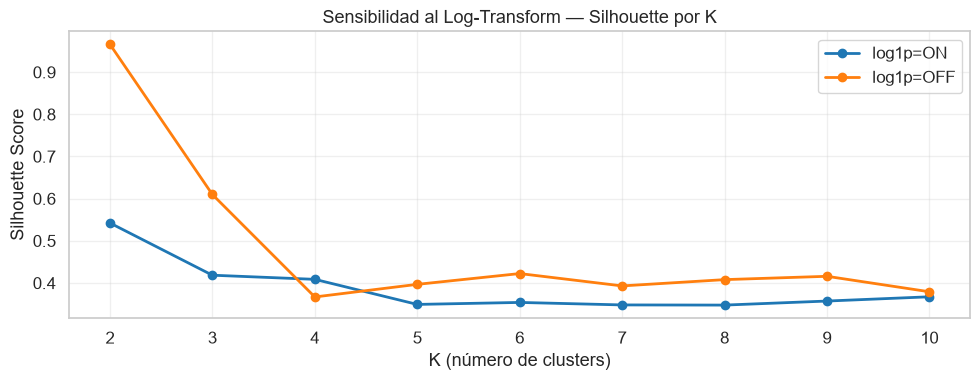


📊 Guardado: ..\data\processed\plots\sensitivity_analysis.png


In [33]:
sensitivity_rows = []

for use_log in [True, False]:
    label_str = "log1p=ON" if use_log else "log1p=OFF"
    X_s, _, _ = prepare_features(df_raw, log_transform=use_log,
                                  skew_threshold=SKEW_THRESHOLD)
    X_sc, _  = scale_features(X_s, method=SCALE_METHOD)
    row = {"configuracion": label_str}
    for k in K_RANGE:
        km  = KMeans(n_clusters=k, init="k-means++", n_init=10,
                     random_state=RANDOM_STATE)
        lbl = km.fit_predict(X_sc)
        row[f"K={k}"] = round(silhouette_score(X_sc, lbl), 4)
    sensitivity_rows.append(row)

sens_df = pd.DataFrame(sensitivity_rows).set_index("configuracion")
print("Silhouette Score — Comparativa Log-Transform ON vs. OFF:")
display(sens_df)

# Gráfico
fig, ax = plt.subplots(figsize=(10, 4))
for i, cfg in enumerate(sens_df.index):
    k_vals = [int(c.split("=")[1]) for c in sens_df.columns]
    ax.plot(k_vals, sens_df.loc[cfg].values, marker="o", linewidth=2,
            label=cfg, color=PALETTE[i])

ax.set_xlabel("K (número de clusters)")
ax.set_ylabel("Silhouette Score")
ax.set_title("Sensibilidad al Log-Transform — Silhouette por K")
ax.legend()
ax.set_xticks(list(K_RANGE))
ax.grid(True, alpha=0.3)
plt.tight_layout()
sens_path = PLOTS_DIR / "sensitivity_analysis.png"
plt.savefig(sens_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"\n📊 Guardado: {sens_path}")

## 13. (Opcional) Visualización 2D con PCA

Proyectamos las features escaladas en los **dos primeros componentes principales**  
para una inspección visual de la separación entre clusters.  
Los centroides K-Means se muestran con marcador ✕.

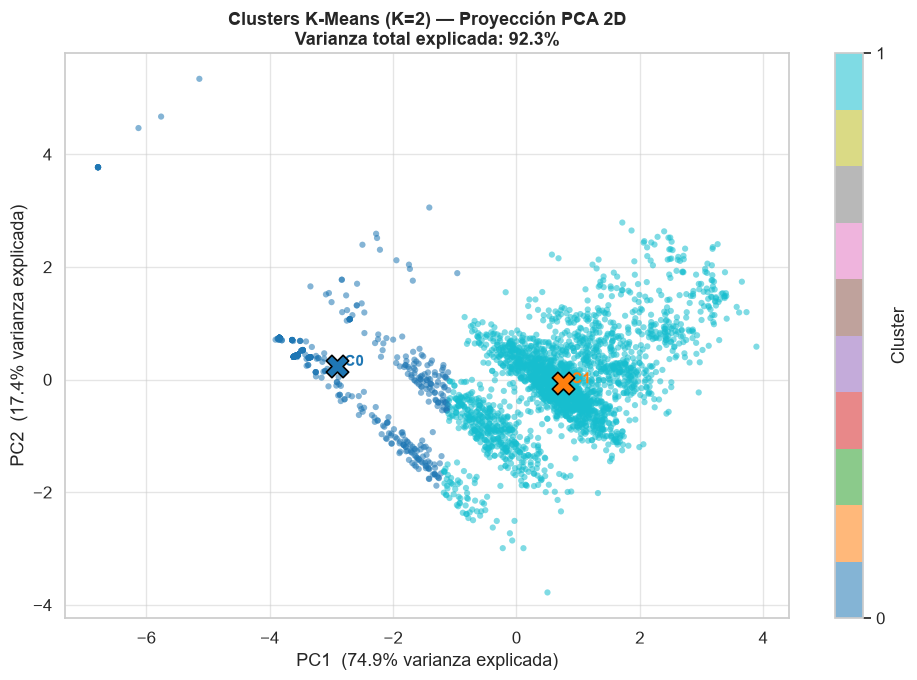

📊 Guardado: ..\data\processed\plots\pca_clusters.png
Varianza PC1+PC2: 92.3%


In [34]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
var_exp = pca.explained_variance_ratio_

fig, ax = plt.subplots(figsize=(10, 7))
scatter = ax.scatter(
    X_pca[:, 0], X_pca[:, 1],
    c=labels, cmap="tab10", alpha=0.55, s=20, edgecolors="none",
)

# Centroides en espacio PCA
centroids_pca = pca.transform(km_model.cluster_centers_)
for i, (cx, cy) in enumerate(centroids_pca):
    ax.scatter(cx, cy, s=260, marker="X", zorder=5,
               color=PALETTE[i % 10], edgecolors="black", linewidths=1.2)
    ax.annotate(f"  C{i}", (cx, cy), fontsize=11,
                fontweight="bold", color=PALETTE[i % 10])

ax.set_xlabel(f"PC1  ({var_exp[0]*100:.1f}% varianza explicada)")
ax.set_ylabel(f"PC2  ({var_exp[1]*100:.1f}% varianza explicada)")
ax.set_title(
    f"Clusters K-Means (K={K_SELECTED}) — Proyección PCA 2D\n"
    f"Varianza total explicada: {sum(var_exp)*100:.1f}%",
    fontsize=13, fontweight="bold",
)
plt.colorbar(scatter, ax=ax, label="Cluster",
             ticks=range(K_SELECTED))
plt.tight_layout()
pca_path = PLOTS_DIR / "pca_clusters.png"
plt.savefig(pca_path, dpi=120, bbox_inches="tight")
display(plt.gcf())
plt.close()
print(f"📊 Guardado: {pca_path}")
print(f"Varianza PC1+PC2: {sum(var_exp)*100:.1f}%")

## 14. Visualización 3D del Espacio RFM

Un punto por **`id_comercio`** en el espacio de las tres variables núcleo del modelo —
**recencia × frecuencia × monto** — coloreado por el cluster asignado por K-Means.

**Decisiones de lectura:**

| Decisión | Motivo |
|----------|--------|
| Ejes `frequency` y `monetary` en escala `log1p` | Skew 6.3 y 4.3 → en escala lineal el 95 % de los comercios se apila contra el origen |
| Ticks rotulados en **escala original** (`$100K`, `$10M`, `300 trx`) | El eje sigue siendo interpretable por negocio pese a la transformación |
| `recency_days` en escala lineal | Skew 1.8 y rango acotado (0–151 días); es directamente legible |
| ✕ = centroide **observado** (media en escala original) | Más interpretable que `cluster_centers_`, que vive en el espacio escalado |
| Los comercios de mayor monto se resaltan con anillo y se listan | Son los que concentran el gap de comisiones; identificarlos por `id_comercio` los hace accionables |

> Las **franjas verticales** visibles en el eje de recencia no son un artefacto del gráfico:
> `recency_days` se concentra en múltiplos de ~30 días porque muchos comercios sólo
> transaccionan una vez al mes.

> ⚠️ Un scatter 3D estático sufre **ambigüedad de profundidad**: la posición aparente de un
> punto depende del ángulo de cámara. Para conclusiones cuantitativas usa el perfil de la
> sección 9; este gráfico es para inspección de **forma y separación** de los segmentos.


In [ ]:
# Gráfico 3D de las variables monetary, recency y frecuencia por id_comercio
def _fmt_cop(v: float) -> str:
    """Formatea un monto en COP con sufijo legible (K / M / MM)."""
    for div, suf in ((1e9, "MM"), (1e6, "M"), (1e3, "K")):
        if v >= div:
            return f"${v / div:,.0f}{suf}"
    return f"${v:,.0f}"


def plot_rfm_3d(
    df_orig: pd.DataFrame,
    labels: np.ndarray,
    log_axes: tuple = ("frequency", "monetary"),
    top_n_labels: int = 4,
    elev: int = 20,
    azim: int = -62,
    save_path: Optional[Path] = None,
) -> pd.DataFrame:
    """Grafica el espacio RFM en 3D: recencia × frecuencia × monto, un punto por comercio.

    Cada punto es un `id_comercio` coloreado por su cluster K-Means. Los ejes
    `frequency` y `monetary` se dibujan en escala `log1p` (skew 6.3 y 4.3) pero se
    rotulan con valores en escala original para que sigan siendo interpretables por
    negocio. El marcador ✕ señala el centroide observado de cada segmento y los
    `top_n_labels` comercios de mayor monto se resaltan con anillo negro.

    Args:
        df_orig: DataFrame con variables en escala natural (pre-transformación),
            incluyendo `id_comercio`, `recency_days`, `frequency` y `monetary`.
        labels: Array 1D con la asignación de cluster por comercio (base-0).
        log_axes: Variables a dibujar en escala log1p.
        top_n_labels: Cuántos comercios de mayor `monetary` resaltar e identificar.
        elev: Elevación de la cámara en grados.
        azim: Azimut de la cámara en grados.
        save_path: Ruta del .png a guardar. Si None, no guarda.

    Returns:
        DataFrame con el centroide observado (media en escala original) por cluster.
    """
    axes_spec = [
        ("recency_days", "Recencia (días desde última trx)",
         [0, 20, 40, 60, 80, 100, 120, 140]),
        ("frequency", "Frecuencia (n.º trx · 6 meses)",
         [0, 1, 3, 10, 30, 100, 300, 1000]),
        ("monetary", "Monto transado (COP)",
         [0, 1e5, 1e6, 1e7, 1e8, 1e9]),
    ]

    df_p = df_orig.copy()
    df_p["cluster"] = labels.astype(int)
    K = int(df_p["cluster"].max()) + 1

    def coord(col, values):
        """Convierte valores a la escala de dibujo del eje."""
        return np.log1p(values) if col in log_axes else values

    xyz = {col: coord(col, df_p[col]) for col, _, _ in axes_spec}

    fig = plt.figure(figsize=(12, 9))
    ax = fig.add_subplot(projection="3d")

    # Clusters grandes primero → los pequeños quedan visibles encima
    for cl in df_p["cluster"].value_counts().index.tolist():
        m = df_p["cluster"] == cl
        ax.scatter(
            xyz["recency_days"][m], xyz["frequency"][m], xyz["monetary"][m],
            color=PALETTE[cl % 10], s=13, alpha=0.40,
            edgecolors="none", depthshade=False,
        )

    # ── Centroides observados (media en escala original) ──────────────────
    centroids = (
        df_p.groupby("cluster")[["recency_days", "frequency", "monetary"]]
        .mean()
        .reset_index()
    )
    for _, row in centroids.iterrows():
        cl = int(row["cluster"])
        cx, cy, cz = (coord(c, row[c]) for c in
                      ("recency_days", "frequency", "monetary"))
        # Halo blanco para que el centroide no se pierda en la nube de puntos
        ax.scatter(cx, cy, cz, marker="X", s=430, depthshade=False,
                   color="white", edgecolors="white", linewidths=2.0)
        ax.scatter(cx, cy, cz, marker="X", s=300, depthshade=False,
                   color=PALETTE[cl % 10], edgecolors="black", linewidths=1.4)
        ax.text(cx, cy, cz, f"  C{cl}", fontsize=12, fontweight="bold",
                color="#22252a", zorder=10)

    # ── Comercios de mayor monto: anillo + listado (evita solapar rótulos) ─
    top = df_p.nlargest(top_n_labels, "monetary") if top_n_labels else df_p.iloc[:0]
    if len(top):
        ax.scatter(
            coord("recency_days", top["recency_days"]),
            coord("frequency", top["frequency"]),
            coord("monetary", top["monetary"]),
            s=70, facecolors="none", edgecolors="#22252a", linewidths=1.6,
            depthshade=False,
        )
        listado = "\n".join(
            f"○ {r.id_comercio}   {_fmt_cop(r.monetary)}   ·   {r.frequency:,.0f} trx"
            f"   ·   R={r.recency_days:.0f}d   ·   C{int(r.cluster)}"
            for r in top.itertuples()
        )
        ax.text2D(
            1.0, 0.90, f"Mayor monto transado\n{listado}",
            transform=ax.transAxes, fontsize=8.5, color="#4c5157",
            va="top", ha="right", linespacing=1.5,
            bbox=dict(boxstyle="round,pad=0.5", facecolor="white",
                      edgecolor="#d9dce0"),
        )

    # ── Ejes: ticks en escala original, etiquetas de negocio ──────────────
    ax.zaxis.set_rotate_label(False)
    setters = (
        (ax.set_xlabel, ax.set_xticks, ax.set_xticklabels, {}),
        (ax.set_ylabel, ax.set_yticks, ax.set_yticklabels, {}),
        (ax.set_zlabel, ax.set_zticks, ax.set_zticklabels, {"rotation": 90}),
    )
    for (col, label, cands), (set_label, set_ticks, set_labels, kw) in zip(
        axes_spec, setters
    ):
        suffix = "  ·  log1p" if col in log_axes else ""
        set_label(f"{label}{suffix}", fontsize=10, labelpad=14, **kw)
        if col in log_axes:
            vals = [c for c in cands if c <= df_p[col].max() * 1.05]
            set_ticks(np.log1p(vals))
            set_labels(
                [_fmt_cop(v) if col == "monetary" else f"{v:,.0f}" for v in vals],
                fontsize=9,
            )

    # ── Estética recesiva de paneles y rejilla ────────────────────────────
    for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
        axis.set_pane_color((1.0, 1.0, 1.0, 0.0))
        axis._axinfo["grid"].update(color="#d9dce0", linewidth=0.6)

    ax.view_init(elev=elev, azim=azim)
    ax.set_box_aspect((1, 1, 0.85), zoom=0.94)
    ax.set_title(
        f"Espacio RFM en 3D — {len(df_p):,} comercios por cluster (K={K})\n"
        "Recencia × Frecuencia × Monto  ·  X = centroide del segmento",
        fontsize=13, fontweight="bold", y=1.0,
    )

    # ── Leyenda categórica: la identidad nunca depende sólo del color ─────
    sizes = df_p["cluster"].value_counts().sort_index()
    handles = [
        Line2D([0], [0], marker="o", linestyle="none", markersize=9,
               markerfacecolor=PALETTE[cl % 10], markeredgecolor="none",
               label=f"Cluster {cl} — {n:,} comercios ({n / len(df_p) * 100:.1f} %)")
        for cl, n in sizes.items()
    ]
    ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(-0.02, 0.90),
              frameon=True, framealpha=0.9, fontsize=9)

    fig.subplots_adjust(left=0.03, right=0.92, top=0.94, bottom=0.05)
    if save_path is not None:
        plt.savefig(save_path, dpi=130, bbox_inches="tight")
    return fig


# ── Ejecutar ──────────────────────────────────────────────────────────────
rfm3d_path = PLOTS_DIR / "rfm_3d_clusters.png"
centroids_3d = plot_rfm_3d(df_orig, labels, save_path=rfm3d_path)
display(plt.gcf())
plt.close()

print(f"📊 Guardado: {rfm3d_path}\n")
print("Centroide observado por segmento (escala original):")
display(centroids_3d.set_index("cluster").round(1))
